In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import requests
from google.colab import drive
! pip install plotly-geo

In [20]:
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [21]:
df = pd.read_parquet("/content/drive/MyDrive/Nino/finished_data/complete_df.parquet")
df.columns

Index(['GEOID', 'date', 'damage_label_t+3', 'damage_label', 'death_label_t+3',
       'death_label', 'damage_antecedent_60', 'damage_antecedent_12',
       'deaths_antecedent_60', 'deaths_antecedent_12',
       'volumetric_soil_water_layer_3', 'precip_prior3', 'precip_prior6',
       'nino_3.4', 'year', 'population', 'pop_density', 'poverty_rate',
       'wind_speed', 'temperature_2m_anomaly',
       'dewpoint_temperature_2m_anomaly', 'hand_vulnerability', 'dist_coast_m',
       'pct_no_vehicle', 'lat', 'lon'],
      dtype='object')

In [22]:
# creating a simple tree without feature scaling or test/valid set just to see the tree

from sklearn.tree import DecisionTreeRegressor

X = df[['damage_antecedent_60',
       'damage_antecedent_12', 'deaths_antecedent_60', 'deaths_antecedent_12',
       'volumetric_soil_water_layer_3', 'precip_prior3', 'precip_prior6',
       'nino_3.4', 'year', 'population', 'pop_density', 'poverty_rate',
       'wind_speed', 'temperature_2m_anomaly',
       'dewpoint_temperature_2m_anomaly', 'hand_vulnerability', 'dist_coast_m',
       'pct_no_vehicle', 'lat', 'lon']]
y = df[['damage_label', 'death_label']]

tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(X,y)

DecisionTreeRegressor(random_state=42)

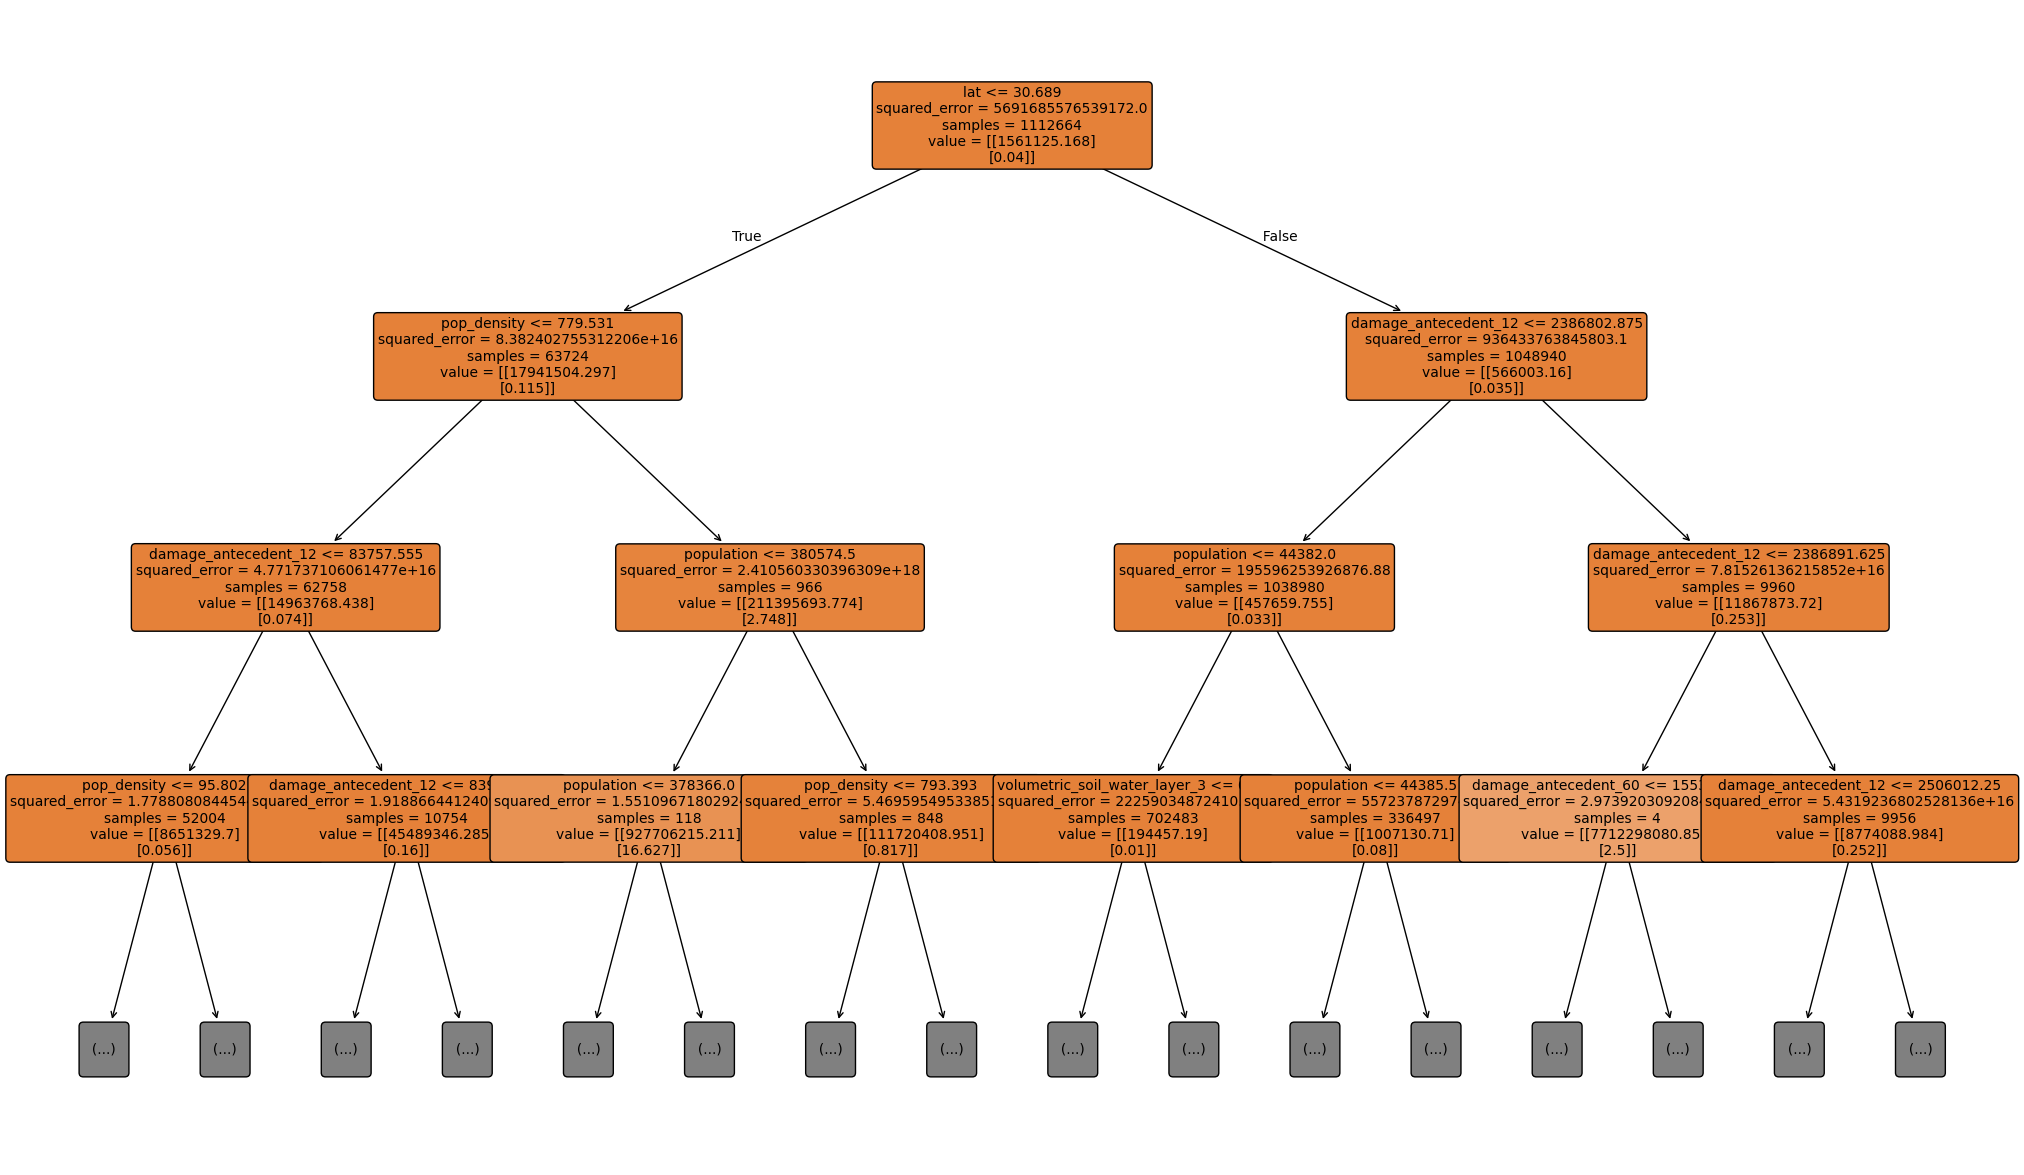

In [23]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(25,15))
plot_tree(
    tree_reg,
    feature_names=['damage_antecedent_60',
       'damage_antecedent_12', 'deaths_antecedent_60', 'deaths_antecedent_12',
       'volumetric_soil_water_layer_3', 'precip_prior3', 'precip_prior6',
       'nino_3.4', 'year', 'population', 'pop_density', 'poverty_rate',
       'wind_speed', 'temperature_2m_anomaly',
       'dewpoint_temperature_2m_anomaly', 'hand_vulnerability', 'dist_coast_m',
       'pct_no_vehicle', 'lat', 'lon'],
    filled=True,
    rounded=True,
    fontsize=10,
    # ax=ax,
    max_depth=3
)
plt.show()

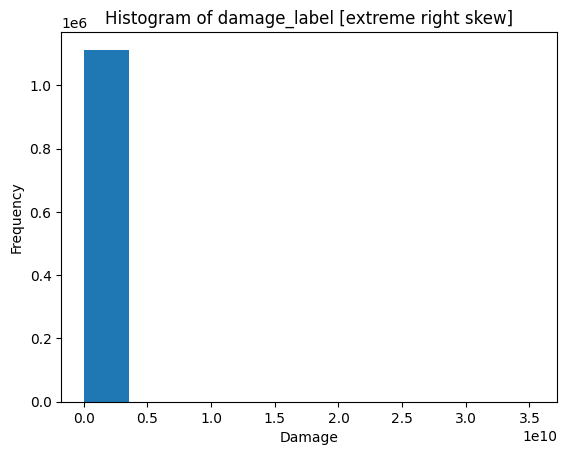

In [24]:
plt.hist(df["damage_label"])
plt.title("Histogram of damage_label [extreme right skew]")
plt.xlabel("Damage")
plt.ylabel("Frequency")

plt.show()

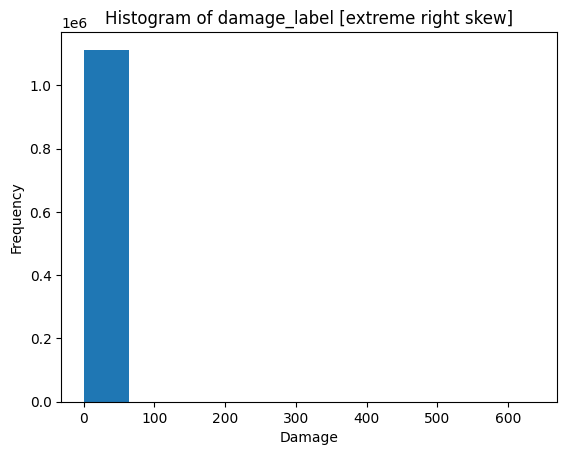

In [25]:
plt.hist(df["death_label"])
plt.title("Histogram of damage_label [extreme right skew]")
plt.xlabel("Damage")
plt.ylabel("Frequency")

plt.show()

In [26]:
df["damage_label"].describe()
# (df["damage_label"] == 0).mean() # 0.849321987590144

,damage_label
count,1.112664e+06
mean,1.561125e+06
std,1.066929e+08
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,3.541137e+10


In [27]:
df["death_label"].describe()
# (df["death_label"] == 0).mean() #0.9840913339516691

,death_label
count,1.112664e+06
mean,3.952136e-02
std,1.775898e+00
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,6.380000e+02


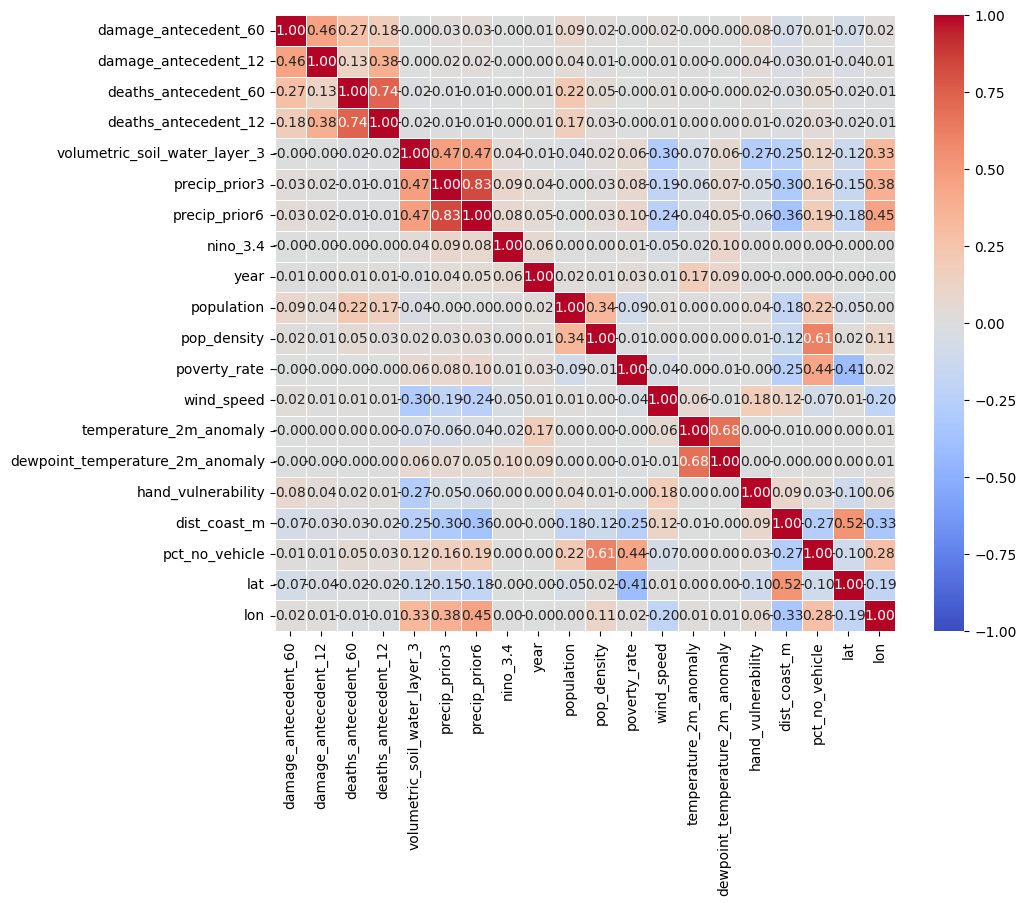

In [28]:
# CORRELATION HEATMAP, see how closely related diff features are using matplotlib and seaborn

import seaborn as sns

correlation_matrix = df[['damage_antecedent_60',
       'damage_antecedent_12', 'deaths_antecedent_60', 'deaths_antecedent_12',
       'volumetric_soil_water_layer_3', 'precip_prior3', 'precip_prior6',
       'nino_3.4', 'year', 'population', 'pop_density', 'poverty_rate',
       'wind_speed', 'temperature_2m_anomaly',
       'dewpoint_temperature_2m_anomaly', 'hand_vulnerability', 'dist_coast_m',
       'pct_no_vehicle', 'lat', 'lon']].corr()
plt.figure(figsize=(10,8))

sns.heatmap(
    correlation_matrix,
    annot=True, # shows the correlations
    cmap="coolwarm",
    vmin=-1, # ensures the color range extends from -1 to 1, the full possible range of correlations
    vmax=1,
    linewidths=0.4,
    fmt=".2f" # rounds to 2 digits
)
plt.show()

In [29]:
# cloropleths to visualize on a county-wide map
import plotly.express as px
import requests

counties_geojson = requests.get("https://raw.githubusercontent.com/plotly/datasets/0c447c47b757ad74edecab31f0d72f849d2e67c2/geojson-counties-fips.json").json()

fig = px.choropleth(
    df,
    geojson=counties_geojson,
    locations="GEOID",
    color="wind_speed",
    animation_frame="year",
    scope="usa"
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

/tmp/ipykernel_2796/802822356.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



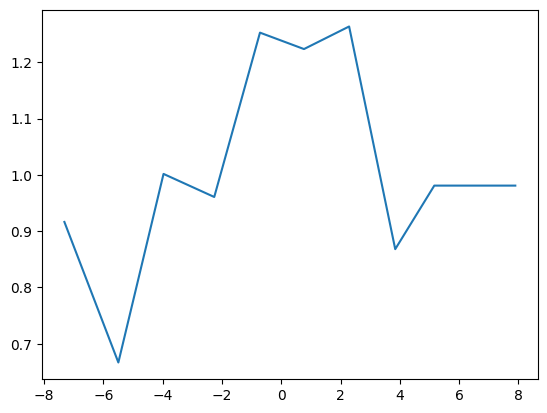

In [44]:
# pretty messed up because the features associated with the targets are 3 months prior
# for example: if heat waves in august produced deaths/damages
# the graph would attribute this to the heat 3 months prior, or the relatively cooler may
# such graphs are counterintuitive and capture delayed seasonal variations more than a recognizable pattern

df["nino_bins"] = pd.cut(df[df["death_label_t+3"] > 0]["temperature_2m_anomaly"], bins=10)
plt.plot(df.groupby("nino_bins")["temperature_2m_anomaly"].mean(), np.log1p(df.groupby("nino_bins")["death_label_t+3"].mean()))
plt.show()